In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

/kaggle/input/fraud-dataset/SOI_2025_Dataset.csv


### 📦 Step 1: Import Required Libraries  
We begin by importing all the necessary libraries for data handling, exploration, modeling, and optimization.  
We’ll use `XGBoost` with GPU acceleration and `LogisticRegression` with Optuna for hyperparameter tuning.

In [2]:
# Basic setup
import numpy as np
import pandas as pd
import warnings
warnings.filterwarnings("ignore")

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Modeling
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score, classification_report

# XGBoost
import xgboost as xgb

# Optimization
import optuna

# Utility
import os
import gc


### 🔍 Step 2: Dataset Exploration for Feature Engineering  
Before cleaning or feature engineering, we explore the dataset to understand variable types, potential leakage, skew, and interaction opportunities.

In [8]:
# Load dataset
data_path = '/kaggle/input/fraud-dataset/SOI_2025_Dataset.csv'
df = pd.read_csv(data_path)

# Preview structure
print(f"Shape: {df.shape}")
display(df.head())

# Basic info
df_info = df.info()

# Summary statistics
display(df.describe().T)

# Target distribution
print("\nTarget Distribution:")
print(df['fraud_bool'].value_counts(normalize=True))

# Check column types
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
non_numeric_cols = df.select_dtypes(exclude=[np.number]).columns.tolist()
print(f"\nNumeric columns: {len(numeric_cols)}")
print(f"Non-numeric columns: {non_numeric_cols}")

# Check nulls
null_counts = df.isnull().sum()
null_counts = null_counts[null_counts > 0]
print(f"\nColumns with missing values:\n{null_counts}")

# Detect constant columns
constant_cols = [col for col in df.columns if df[col].nunique() <= 1]
print(f"\nConstant columns: {constant_cols}")

# Correlation matrix
corr_matrix = df[numeric_cols].corr().abs()
high_corr_pairs = (
    corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
    .stack()
    .sort_values(ascending=False)
)
print("\nHighly correlated feature pairs (corr > 0.9):")
print(high_corr_pairs[high_corr_pairs > 0.9])


Shape: (1000000, 32)


,fraud_bool,income,name_email_similarity,prev_address_months_count,current_address_months_count,customer_age,days_since_request,intended_balcon_amount,payment_type,zip_count_4w,...,has_other_cards,proposed_credit_limit,foreign_request,source,session_length_in_minutes,device_os,keep_alive_session,device_distinct_emails_8w,device_fraud_count,month
0,0,0.7,0.062288,-1,24,50,0.016740,-0.871747,AB,3430,...,1,200.0,0,INTERNET,6.804428,other,0,1,0,0
1,0,0.9,0.098433,-1,310,50,0.019002,-1.023805,AB,3492,...,1,1500.0,0,INTERNET,1.412211,macintosh,0,1,0,0
2,0,0.6,0.116962,-1,189,60,0.047064,-1.206121,AB,4621,...,0,200.0,0,INTERNET,14.488562,other,1,1,0,0
3,0,0.3,0.059078,10,40,60,0.008007,-0.075908,AA,1697,...,1,200.0,0,INTERNET,6.152497,linux,1,1,0,0
4,0,0.1,0.689959,-1,128,30,2.513544,-1.108190,AD,1431,...,0,200.0,0,INTERNET,5.599853,other,0,1,0,0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000000 entries, 0 to 999999
Data columns (total 32 columns):
 #   Column                            Non-Null Count    Dtype  
---  ------                            --------------    -----  
 0   fraud_bool                        1000000 non-null  int64  
 1   income                            1000000 non-null  float64
 2   name_email_similarity             1000000 non-null  float64
 3   prev_address_months_count         1000000 non-null  int64  
 4   current_address_months_count      1000000 non-null  int64  
 5   customer_age                      1000000 non-null  int64  
 6   days_since_request                1000000 non-null  float64
 7   intended_balcon_amount            1000000 non-null  float64
 8   payment_type                      1000000 non-null  object 
 9   zip_count_4w                      1000000 non-null  int64  
 10  velocity_6h                       1000000 non-null  float64
 11  velocity_24h                      1000

,count,mean,std,min,25%,50%,75%,max
fraud_bool,1000000.0,0.011029,0.104438,0.000000e+00,0.000000,0.000000,0.000000,1.000000
income,1000000.0,0.574544,0.288768,1.000000e-01,0.300000,0.600000,0.800000,0.900000
name_email_similarity,1000000.0,0.488628,0.291431,5.024707e-08,0.214787,0.489745,0.754373,1.000000
prev_address_months_count,1000000.0,14.824523,43.231383,-1.000000e+00,-1.000000,-1.000000,-1.000000,399.000000
current_address_months_count,1000000.0,99.381393,94.558757,-1.000000e+00,26.000000,64.000000,154.000000,429.000000
customer_age,1000000.0,41.304140,13.804710,1.000000e+01,30.000000,50.000000,50.000000,90.000000
days_since_request,1000000.0,0.911917,4.986861,3.112791e-08,0.007430,0.015650,0.026928,76.577505
intended_balcon_amount,1000000.0,8.638806,20.573558,-1.573989e+01,-1.178013,-0.831185,0.078508,112.702504
zip_count_4w,1000000.0,1567.400554,1009.619023,1.000000e+00,901.000000,1236.000000,1909.000000,6650.000000
velocity_6h,1000000.0,5685.095489,3001.707767,-1.741097e+02,3470.243411,5408.425641,7653.990129,16801.339834



Target Distribution:
fraud_bool
0    0.988971
1    0.011029
Name: proportion, dtype: float64

Numeric columns: 27
Non-numeric columns: ['payment_type', 'employment_status', 'housing_status', 'source', 'device_os']

Columns with missing values:
Series([], dtype: int64)

Constant columns: ['device_fraud_count']

Highly correlated feature pairs (corr > 0.9):
Series([], dtype: float64)


### 🧹 Step 3: Data Cleaning and Feature Engineering  
We drop constant columns, fix placeholder values like `-1`, clip extreme outliers, and one-hot encode categorical variables.  
Additionally, we create new statistical and ratio features that may help both models.

In [9]:
# Drop constant column
df.drop(columns=['device_fraud_count'], inplace=True)

# Fix placeholder values (-1) in certain columns → treat as missing
bad_values = ['prev_address_months_count', 'current_address_months_count',
              'bank_months_count', 'session_length_in_minutes',
              'device_distinct_emails_8w']

for col in bad_values:
    df[col] = df[col].replace(-1, np.nan)

# Fill missing values with median (robust to outliers)
df.fillna(df.median(numeric_only=True), inplace=True)

# Cap skewed numerical values at 99.5 percentile (anti-outlier)
for col in df.select_dtypes(include=[np.number]).columns:
    if col != 'fraud_bool':
        upper_limit = df[col].quantile(0.995)
        df[col] = np.clip(df[col], None, upper_limit)

# One-hot encode categorical columns (XGBoost handles this well)
categorical_cols = ['payment_type', 'employment_status', 'housing_status', 'source', 'device_os']
df = pd.get_dummies(df, columns=categorical_cols, drop_first=True)

# Create statistical interaction features
feature_cols = [col for col in df.columns if col != 'fraud_bool']
df['feature_sum'] = df[feature_cols].sum(axis=1)
df['feature_mean'] = df[feature_cols].mean(axis=1)
df['feature_std'] = df[feature_cols].std(axis=1)
df['feature_max'] = df[feature_cols].max(axis=1)
df['feature_min'] = df[feature_cols].min(axis=1)
df['feature_range'] = df['feature_max'] - df['feature_min']


### ⚙️ Step 4: Logistic Regression Tuning with Optuna  
We use Optuna to find the best `C` and `class_weight` hyperparameters for a Logistic Regression model using the `liblinear` solver.  
After tuning, we visualize optimization progress and feature importance using Optuna's built-in tools.

[I 2025-07-15 03:38:11,700] A new study created in memory with name: LogReg F1 Optimization


  0%|          | 0/50 [00:00<?, ?it/s]

[I 2025-07-15 03:38:27,482] Trial 0 finished with value: 0.08179865649134031 and parameters: {'C': 0.005751005177512457, 'class_weight': 'balanced'}. Best is trial 0 with value: 0.08179865649134031.
[I 2025-07-15 03:38:43,474] Trial 1 finished with value: 0.024021352313167262 and parameters: {'C': 2.7241349312980323, 'class_weight': None}. Best is trial 0 with value: 0.08179865649134031.
[I 2025-07-15 03:38:52,124] Trial 2 finished with value: 0.0 and parameters: {'C': 0.00039728293816572815, 'class_weight': None}. Best is trial 0 with value: 0.08179865649134031.
[I 2025-07-15 03:39:00,933] Trial 3 finished with value: 0.0 and parameters: {'C': 0.0007551460702669273, 'class_weight': None}. Best is trial 0 with value: 0.08179865649134031.
[I 2025-07-15 03:39:14,429] Trial 4 finished with value: 0.0817239647536867 and parameters: {'C': 0.003409073698999795, 'class_weight': 'balanced'}. Best is trial 0 with value: 0.08179865649134031.
[I 2025-07-15 03:39:37,025] Trial 5 finished with valu

AttributeError: 'Axes' object has no attribute 'show'

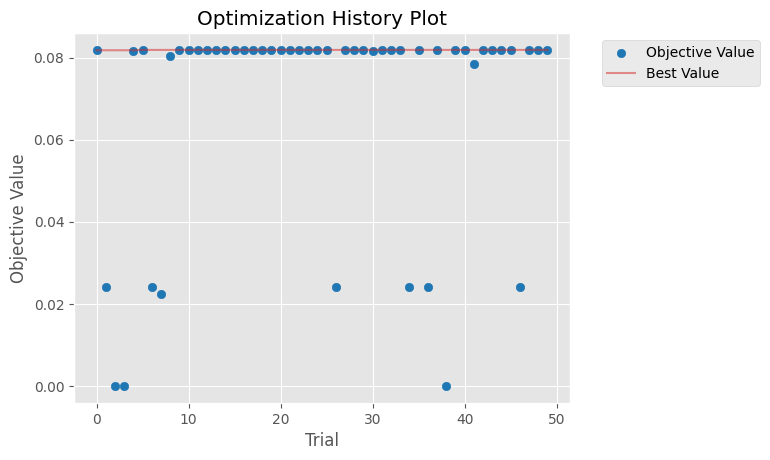

In [12]:
import optuna.visualization.matplotlib as optuna_viz

# ⛔ Force only liblinear solver
def objective_logreg(trial):
    C = trial.suggest_float("C", 1e-4, 10.0, log=True)
    class_weight = trial.suggest_categorical("class_weight", [None, "balanced"])

    model = LogisticRegression(
        C=C,
        solver="liblinear",  # fixed
        class_weight=class_weight,
        max_iter=1000,
        random_state=42,
        n_jobs=-1,
    )

    model.fit(X_train_scaled, y_train)
    preds = model.predict(X_valid_scaled)
    return f1_score(y_valid, preds)

# Run Optuna study
study_lr = optuna.create_study(direction="maximize", study_name="LogReg F1 Optimization")
study_lr.optimize(objective_logreg, n_trials=50, show_progress_bar=True)

# Best results
print("✅ Best Hyperparameters:")
print(study_lr.best_params)

# Visualize optimization history
optuna_viz.plot_optimization_history(study_lr).show()

# Visualize feature importance from hyperparameter tuning
optuna_viz.plot_param_importances(study_lr).show()


### 📊 Step 5: Evaluate Tuned Logistic Regression  
We now train Logistic Regression using the best parameters from Optuna and evaluate its classification performance on the validation set.

In [13]:
# Re-train best Logistic Regression model
best_lr = LogisticRegression(
    **study_lr.best_params,
    solver="liblinear",
    max_iter=1000,
    random_state=42,
    n_jobs=-1
)
best_lr.fit(X_train_scaled, y_train)
preds_lr = best_lr.predict(X_valid_scaled)

# Evaluate
print("🧾 Classification Report for Logistic Regression:")
print(classification_report(y_valid, preds_lr, digits=4))


🧾 Classification Report for Logistic Regression:
              precision    recall  f1-score   support

           0     0.9974    0.7991    0.8873    197794
           1     0.0431    0.8114    0.0819      2206

    accuracy                         0.7993    200000
   macro avg     0.5202    0.8053    0.4846    200000
weighted avg     0.9868    0.7993    0.8784    200000



### 🎯 Step 6: Threshold Tuning for Logistic Regression  
Instead of using the default 0.5 threshold, we search for the best threshold that maximizes F1-score on the validation set.

In [14]:
from sklearn.metrics import f1_score
import numpy as np

# Get predicted probabilities for positive class
probs_lr = best_lr.predict_proba(X_valid_scaled)[:, 1]

# Search thresholds from 0.01 to 0.99
thresholds = np.arange(0.01, 1.0, 0.01)
f1_scores = [f1_score(y_valid, (probs_lr > t).astype(int)) for t in thresholds]

# Best threshold
best_threshold_lr = thresholds[np.argmax(f1_scores)]
best_f1_lr = np.max(f1_scores)

print(f"✅ Best threshold for Logistic Regression: {best_threshold_lr:.4f}")
print(f"🎯 Best F1-score: {best_f1_lr:.4f}")


✅ Best threshold for Logistic Regression: 0.9300
🎯 Best F1-score: 0.2092


### 📈 Logistic Regression: F1-Score vs Threshold

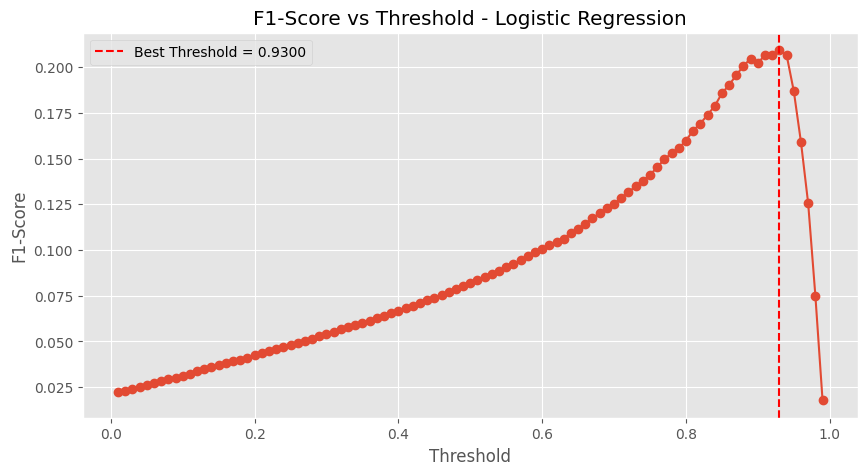

In [15]:
plt.figure(figsize=(10, 5))
plt.plot(thresholds, f1_scores, marker='o')
plt.axvline(best_threshold_lr, color='red', linestyle='--', label=f'Best Threshold = {best_threshold_lr:.4f}')
plt.title("F1-Score vs Threshold - Logistic Regression")
plt.xlabel("Threshold")
plt.ylabel("F1-Score")
plt.legend()
plt.grid(True)
plt.show()


Getting data ready for xgboost

In [20]:

# Replace -1 in known bad columns
bad_values = ['prev_address_months_count', 'current_address_months_count',
              'bank_months_count', 'session_length_in_minutes',
              'device_distinct_emails_8w']
df[bad_values] = df[bad_values].replace(-1, np.nan)

# Fill missing with median
df.fillna(df.median(numeric_only=True), inplace=True)

# Cap skewed values at 99.5 percentile
for col in df.select_dtypes(include=[np.number]).columns:
    if col != 'fraud_bool':
        cap = df[col].quantile(0.995)
        df[col] = np.clip(df[col], None, cap)

# One-hot encode categoricals only if they still exist
categorical_cols = ['payment_type', 'employment_status', 'housing_status', 'source', 'device_os']
existing_cats = [col for col in categorical_cols if col in df.columns]
df = pd.get_dummies(df, columns=existing_cats, drop_first=True)

# Create interaction features from numeric columns only
numeric_cols = df.select_dtypes(include=[np.number]).drop(columns='fraud_bool').columns

df['feature_sum'] = df[numeric_cols].sum(axis=1).astype(np.float32)
df['feature_mean'] = df[numeric_cols].mean(axis=1).astype(np.float32)
df['feature_std'] = df[numeric_cols].std(axis=1).astype(np.float32)
df['feature_max'] = df[numeric_cols].max(axis=1).astype(np.float32)
df['feature_min'] = df[numeric_cols].min(axis=1).astype(np.float32)
df['feature_range'] = (df['feature_max'] - df['feature_min']).astype(np.float32)


In [21]:
X = df.drop(columns='fraud_bool')
y = df['fraud_bool']
X_train, X_valid, y_train, y_valid = train_test_split(X, y, stratify=y, test_size=0.2, random_state=42)

# XGBoost DMatrix inputs
dtrain = xgb.DMatrix(X_train, label=y_train)
dvalid = xgb.DMatrix(X_valid, label=y_valid)


### ⚡ Step 7: XGBoost (GPU) Tuning with Optuna  
We now tune XGBoost using GPU acceleration and Optuna. We optimize tree depth, learning rate, regularization, and class imbalance handling (via `scale_pos_weight`) to maximize F1-score on the validation set.

In [22]:
# Set up DMatrix
dtrain = xgb.DMatrix(X_train, label=y_train)
dvalid = xgb.DMatrix(X_valid, label=y_valid)

def objective_xgb(trial):
    params = {
        "objective": "binary:logistic",
        "eval_metric": "logloss",  # metric used during training, we optimize F1 manually
        "tree_method": "gpu_hist",
        "gpu_id": 0,
        "max_depth": trial.suggest_int("max_depth", 3, 10),
        "learning_rate": trial.suggest_float("learning_rate", 1e-3, 0.3, log=True),
        "subsample": trial.suggest_float("subsample", 0.5, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.5, 1.0),
        "reg_alpha": trial.suggest_float("reg_alpha", 0.0, 10.0),
        "reg_lambda": trial.suggest_float("reg_lambda", 0.0, 10.0),
        "scale_pos_weight": trial.suggest_float("scale_pos_weight", 10, 150),
        "verbosity": 0
    }

    model = xgb.train(
        params,
        dtrain,
        num_boost_round=500,
        evals=[(dvalid, "validation")],
        early_stopping_rounds=30,
        verbose_eval=False
    )

    preds = model.predict(dvalid)
    preds_binary = (preds > 0.5).astype(int)
    return f1_score(y_valid, preds_binary)

# Run Optuna tuning
print("🔍 Tuning XGBoost with GPU using Optuna...")
study_xgb = optuna.create_study(direction="maximize", study_name="XGBoost F1")
study_xgb.optimize(objective_xgb, n_trials=50, show_progress_bar=True)

# Save best params
print("✅ Best Hyperparameters for XGBoost:")
print(study_xgb.best_params)


[I 2025-07-15 04:04:54,146] A new study created in memory with name: XGBoost F1


🔍 Tuning XGBoost with GPU using Optuna...


  0%|          | 0/50 [00:00<?, ?it/s]

[I 2025-07-15 04:05:08,828] Trial 0 finished with value: 0.119378829332203 and parameters: {'max_depth': 10, 'learning_rate': 0.006440561364761565, 'subsample': 0.5512792963245573, 'colsample_bytree': 0.5080063019887061, 'reg_alpha': 6.432841941334782, 'reg_lambda': 8.598083259077296, 'scale_pos_weight': 91.81277774729202}. Best is trial 0 with value: 0.119378829332203.
[I 2025-07-15 04:05:13,309] Trial 1 finished with value: 0.17509891405000422 and parameters: {'max_depth': 3, 'learning_rate': 0.007815331680636447, 'subsample': 0.6068613068732944, 'colsample_bytree': 0.8416302019152655, 'reg_alpha': 6.939941304859982, 'reg_lambda': 9.365207573205051, 'scale_pos_weight': 30.876992530326778}. Best is trial 1 with value: 0.17509891405000422.
[I 2025-07-15 04:05:26,392] Trial 2 finished with value: 0.21826565902395284 and parameters: {'max_depth': 10, 'learning_rate': 0.018117291468487066, 'subsample': 0.8159790803892463, 'colsample_bytree': 0.6583470036882586, 'reg_alpha': 1.568527850406

### 🎯 Step 8: Train Final XGBoost Model & Tune Threshold  
We now train XGBoost with the best parameters from Optuna and tune the classification threshold for optimal F1-score.


In [25]:
# Train final XGBoost model
best_params = study_xgb.best_params
best_params.update({
    "objective": "binary:logistic",
    "eval_metric": "logloss",
    "tree_method": "gpu_hist",
    "gpu_id": 0,
    "verbosity": 0
})

final_xgb = xgb.train(
    best_params,
    dtrain,
    num_boost_round=500,
    evals=[(dvalid, "validation")],
    early_stopping_rounds=30,
    verbose_eval=False
)



### 🎯 Step 9: Threshold Tuning for XGBoost  
We now find the optimal threshold that maximizes F1-score using the probability output from XGBoost. We also plot F1 vs. threshold.


In [26]:
# Predict probabilities on validation set
probs_xgb = final_xgb.predict(dvalid)

# Find best threshold
thresholds = np.arange(0.01, 1.0, 0.01)
f1_scores_xgb = [f1_score(y_valid, (probs_xgb > t).astype(int)) for t in thresholds]

best_threshold_xgb = thresholds[np.argmax(f1_scores_xgb)]
best_f1_xgb = np.max(f1_scores_xgb)

print(f"✅ Best threshold for XGBoost: {best_threshold_xgb:.4f}")
print(f"🎯 Best F1-score from XGBoost: {best_f1_xgb:.4f}")


✅ Best threshold for XGBoost: 0.5100
🎯 Best F1-score from XGBoost: 0.2430


### 🧾 Step 10: Model Comparison  
We compare both tuned models (Logistic Regression and XGBoost) using their best thresholds and print classification reports.


In [27]:
# Logistic Regression Final Prediction
final_preds_lr = (probs_lr > best_threshold_lr).astype(int)

# XGBoost Final Prediction
final_preds_xgb = (probs_xgb > best_threshold_xgb).astype(int)

# Reports
print("📌 Logistic Regression Report:")
print(classification_report(y_valid, final_preds_lr, digits=4))

print("\n📌 XGBoost Report:")
print(classification_report(y_valid, final_preds_xgb, digits=4))


📌 Logistic Regression Report:
              precision    recall  f1-score   support

           0     0.9913    0.9905    0.9909    197794
           1     0.2022    0.2167    0.2092      2206

    accuracy                         0.9819    200000
   macro avg     0.5967    0.6036    0.6000    200000
weighted avg     0.9826    0.9819    0.9822    200000


📌 XGBoost Report:
              precision    recall  f1-score   support

           0     0.9922    0.9870    0.9895    197794
           1     0.2042    0.3001    0.2430      2206

    accuracy                         0.9794    200000
   macro avg     0.5982    0.6435    0.6163    200000
weighted avg     0.9835    0.9794    0.9813    200000



### 💾 Step 11: Save Tuned Models  
We now save both models to disk so they can be reused later for predictions or deployment.


In [28]:
import joblib

# Save Logistic Regression
joblib.dump(best_lr, "logistic_regression_model.pkl")

# Save Scaler (important if reusing later)
joblib.dump(scaler, "scaler.pkl")

# Save XGBoost model
final_xgb.save_model("xgboost_model.json")

print("✅ Models saved:")
print("📁 logistic_regression_model.pkl")
print("📁 scaler.pkl")
print("📁 xgboost_model.json")


✅ Models saved:
📁 logistic_regression_model.pkl
📁 scaler.pkl
📁 xgboost_model.json
